# Pós-processamento: maior componente + buracos

In [1]:
import sys
from pathlib import Path

# O kernel inicia na pasta DESTE caderno — localiza a raiz do projeto:
RAIZ = Path.cwd()
if not (RAIZ / "src" / "leitura.py").exists():
    RAIZ = RAIZ.parent          # kernel começou dentro de notebooks/
sys.path.insert(0, str(RAIZ))   # raiz no path -> 'from src...' funciona

# Imports padrão de todos os cadernos:
from src.leitura import (PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem,
                         nome_da_mascara, criar_pastas_resultados, auditar_base)
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("raiz do projeto:", RAIZ)

raiz do projeto: /home/isadora/Documentos/ProcessIMg


In [2]:
import cv2

from src.preprocessamento import para_cinza
from src.segmentacao import segmentar_otsu, sobrepor
from src.morfologia import limpar_mascara, maior_componente, preencher_buracos, pos_processar

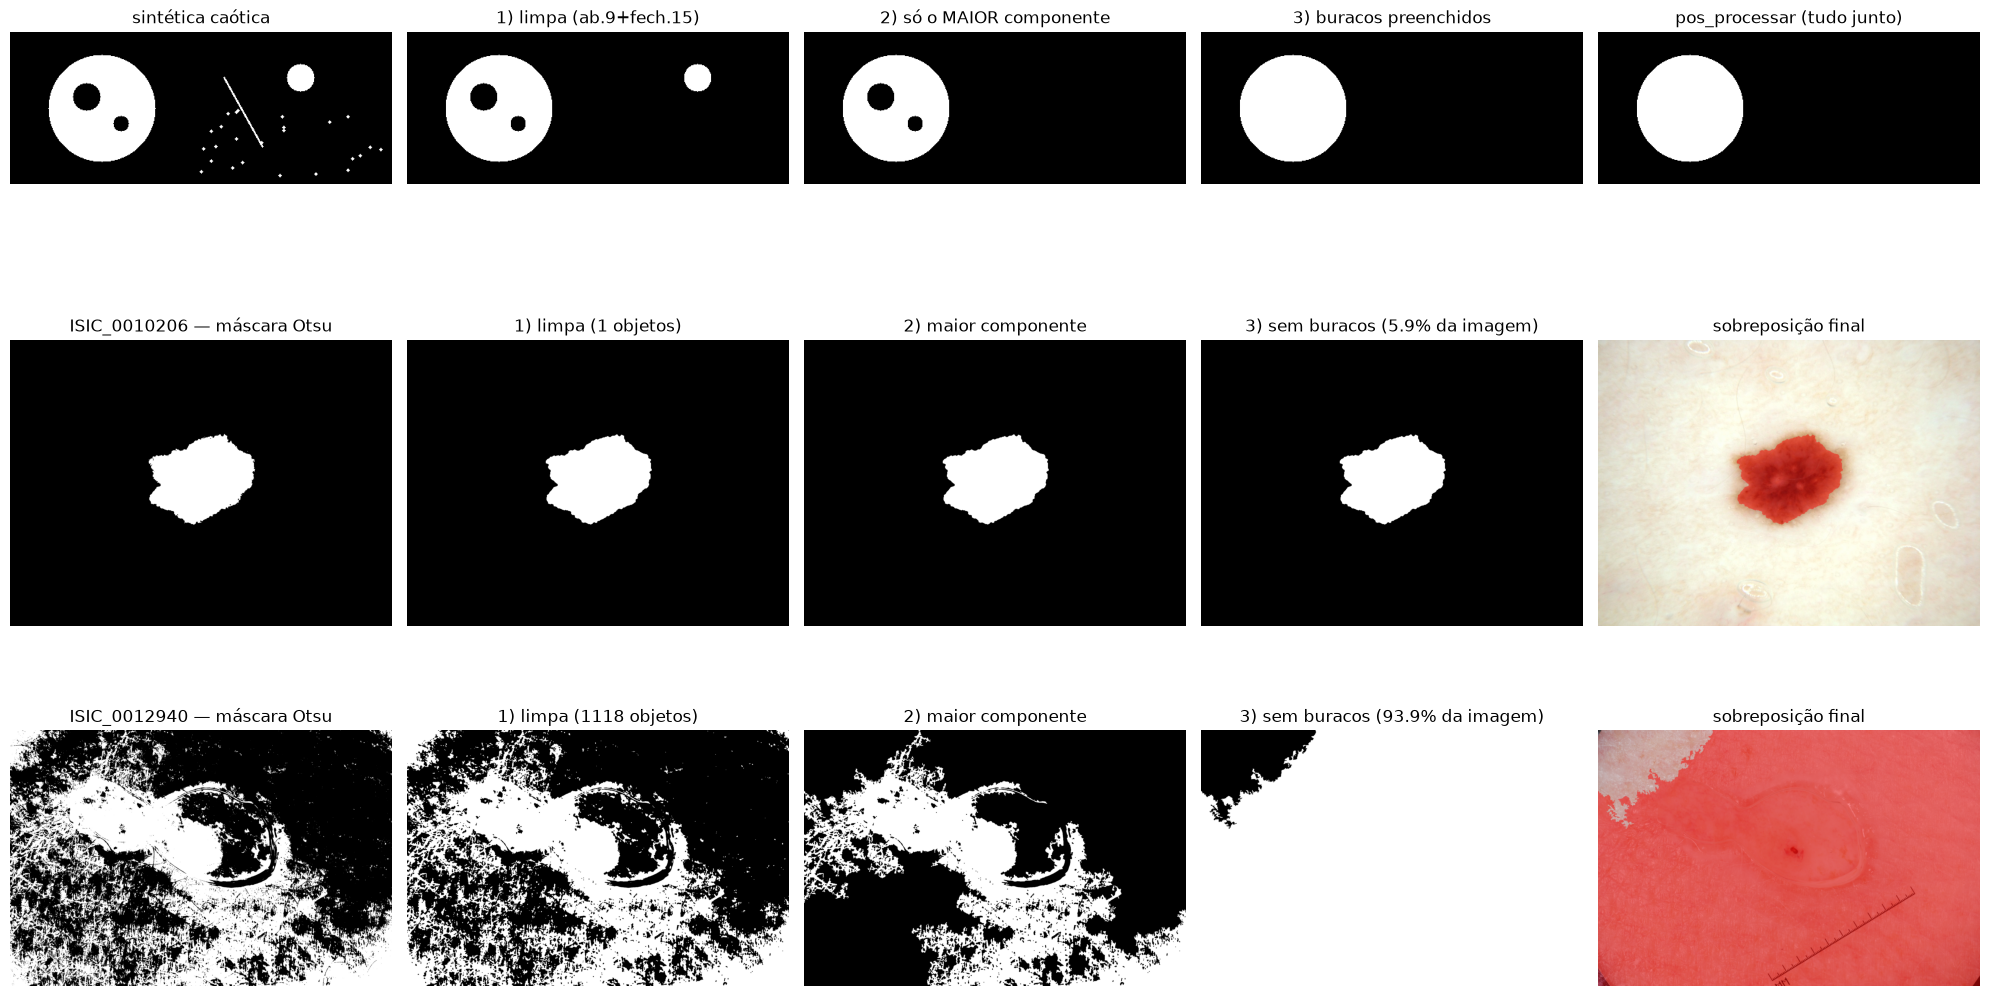

In [3]:
# linha sintética: blob com buracos + falso positivo pequeno + fio + ruído
sintetica = np.zeros((200, 500), dtype=np.uint8)
cv2.circle(sintetica, (120, 100), 70, 255, -1)
cv2.circle(sintetica, (100, 85), 18, 0, -1)
cv2.circle(sintetica, (145, 120), 10, 0, -1)
cv2.circle(sintetica, (380, 60), 18, 255, -1)          # falso positivo pequeno
cv2.line(sintetica, (280, 60), (330, 150), 255, 2)     # fio
for _ in range(25):
    x, y = np.random.randint(250, 490), np.random.randint(100, 190)
    cv2.circle(sintetica, (int(x), int(y)), 2, 255, -1)

fig, axes = plt.subplots(3, 5, figsize=(20, 12))

etapas_sint = [
    (sintetica, "sintética caótica"),
    (limpar_mascara(sintetica, 9, 15), "1) limpa (ab.9+fech.15)"),
    (maior_componente(limpar_mascara(sintetica, 9, 15)), "2) só o MAIOR componente"),
    (preencher_buracos(maior_componente(limpar_mascara(sintetica, 9, 15))), "3) buracos preenchidos"),
    (pos_processar(sintetica, 9, 15), "pos_processar (tudo junto)"),
]
for j, (img, tit) in enumerate(etapas_sint):
    axes[0, j].imshow(img, cmap="gray")
    axes[0, j].set_title(tit)
    axes[0, j].axis("off")

for i, nome in enumerate(["ISIC_0010206.jpg", "ISIC_0012940.jpg"], start=1):
    img = carregar_imagem(PASTA_IMAGENS / nome)
    cinza = para_cinza(img)
    msk = segmentar_otsu(cinza)
    nome_curto = Path(nome).stem
    final = pos_processar(msk)
    n_antes = cv2.connectedComponentsWithStats(limpar_mascara(msk), 8)[0] - 1
    frac = final.mean() / 255
    painel = [
        (msk, f"{nome_curto} — máscara Otsu"),
        (limpar_mascara(msk), f"1) limpa ({n_antes} objetos)"),
        (maior_componente(limpar_mascara(msk)), "2) maior componente"),
        (final, f"3) sem buracos ({frac*100:.1f}% da imagem)"),
        (sobrepor(img, final), "sobreposição final"),
    ]
    for j, (p_img, tit) in enumerate(painel):
        axes[i, j].imshow(p_img if p_img.ndim == 3 else p_img, cmap=None if p_img.ndim == 3 else "gray")
        axes[i, j].set_title(tit)
        axes[i, j].axis("off")

fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "morfologia" / "pos_processamento.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close(fig)